In [1]:
cd /content/drive/MyDrive/ColabNotebooks

/content/drive/MyDrive/ColabNotebooks


In [6]:
# 한글 폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 1 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (10.1 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 117528 files and direct

In [4]:
# [MP2-1] 데이터 전처리
import pandas as pd
import os
from sklearn.preprocessing import LabelEncoder

if os.path.exists("busan_bus_raw.csv"):
    df = pd.read_csv("busan_bus_raw.csv")

    #  컬럼 타입 변환
    df['tzon'] = pd.to_numeric(df['tzon'], errors='coerce')
    df['sttn_seq'] = pd.to_numeric(df['sttn_seq'], errors='coerce')
    df['cgst'] = pd.to_numeric(df['cgst'], errors='coerce')

    # 요일 매핑 (문자 -> 숫자)
    day_map = {'월요일': 0, '화요일': 1, '수요일': 2, '목요일': 3, '금요일': 4, '토요일': 5, '일요일': 6}
    df['day_num'] = df['dow_nm'].map(day_map)

    # 노선 ID 인코딩
    le = LabelEncoder()
    df['route_num'] = le.fit_transform(df['rte_id'].astype(str))

    # 결측치 제거
    df = df.dropna(subset=['tzon', 'sttn_seq', 'cgst', 'day_num', 'route_num'])

    # 정제된 데이터 저장
    df.to_csv("busan_bus_cleaned.csv", index=False)

    print(f"[MP2-1] 전처리 완료: {len(df)}건 정제.")
    print(df[['tzon', 'sttn_seq', 'cgst', 'route_num']].head())

[MP2-1] 전처리 완료: 3000건 정제.
   tzon  sttn_seq  cgst  route_num
0     4         1     2          0
1     4         1     7          0
2     5         1     4          0
3     6         1     2          0
4     6         1     2          0


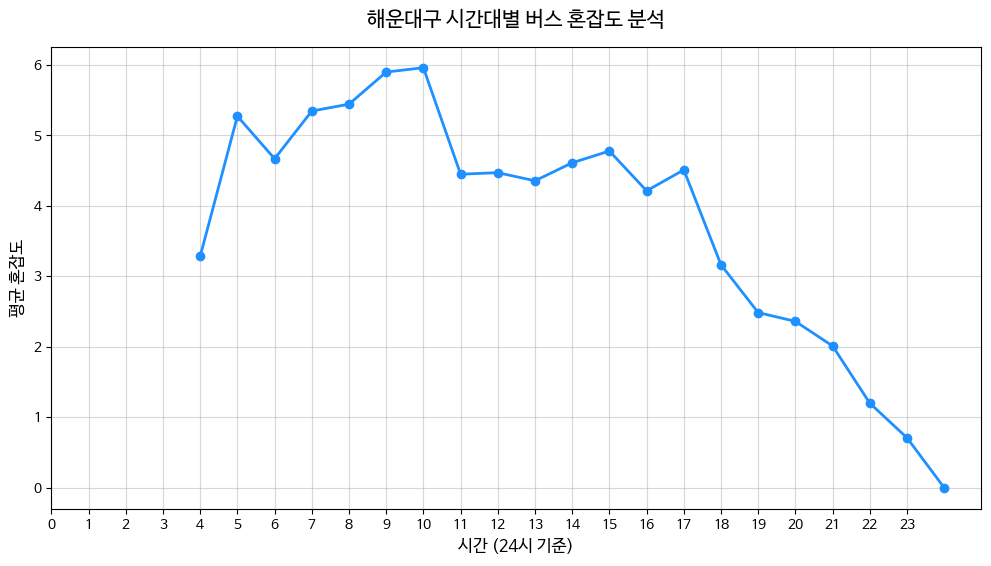

In [6]:
# [MP2-2] 데이터 시각화
import matplotlib.pyplot as plt
import pandas as pd
import os

# 한글 폰트 설정
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False


if os.path.exists("busan_bus_cleaned.csv"):
    df_eda = pd.read_csv("busan_bus_cleaned.csv")

    plt.figure(figsize=(12, 6))

    # 시간대별(tzon) 평균 혼잡도(cgst) 그래프
    df_eda.groupby('tzon')['cgst'].mean().plot(kind='line', marker='o', color='dodgerblue', linewidth=2)

    plt.title("해운대구 시간대별 버스 혼잡도 분석", fontsize=15, pad=15)
    plt.xlabel("시간 (24시 기준)", fontsize=12)
    plt.ylabel("평균 혼잡도", fontsize=12)

    plt.xticks(range(0, 24)) # 0~23시
    plt.grid(alpha=0.5)
    plt.show()

else:
    print("데이터 파일 없음")